# 🕵️ Dark Pattern Detection — MemeCLIP
**Runtime → T4 GPU → Run all cells top to bottom**

## Step 1: Install

In [12]:
!pip install -q "pytorch-lightning==2.3.0" "torchmetrics==1.4.0" yacs ftfy regex
!pip install -q git+https://github.com/openai/CLIP.git
!pip install -q scikit-learn matplotlib seaborn Pillow
import torch, numpy as np
print(f"numpy:{np.__version__} | torch:{torch.__version__} | cuda:{torch.cuda.is_available()}")
assert torch.cuda.is_available(), "NO GPU — Runtime → Change runtime type → T4 GPU"

  Preparing metadata (setup.py) ... done
numpy:2.0.2 | torch:2.9.0+cu126 | cuda:True


## Step 2: Mount Drive & Paths

In [13]:
import os, torch

DATASET_DIR       = "/kaggle/input/datasets/rohitnegii/dark-dataset/ContextRico-DP-20260312T193617Z-1-001/ContextRico-DP"
GROUND_TRUTH_PATH = "/kaggle/input/datasets/rohitnegii/dark-dataset/ContextRico-DP-20260312T193617Z-1-001/ContextRico-DP/groundtrue.json"
WORK_DIR          = "/kaggle/working/dark_pattern"
CHECKPOINT_DIR    = "/kaggle/working/dark_pattern/checkpoints"
ORGANISED_DIR     = "/kaggle/working/DarkPattern_Organised"

os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

assert os.path.exists(DATASET_DIR),       f"NOT FOUND: {DATASET_DIR}"
assert os.path.exists(GROUND_TRUTH_PATH), f"NOT FOUND: {GROUND_TRUTH_PATH}"
print("✅ Paths OK")

✅ Paths OK


## Step 3: Organise Images

In [14]:
import json, shutil
from pathlib import Path
from collections import defaultdict

VALID_CLASSES = ["Hard to Close","Default Choice","False Hierarchy",
                 "Nagging","Pay to Avoid Ad","Disguised Ad"]

for cls in VALID_CLASSES:
    os.makedirs(os.path.join(ORGANISED_DIR, cls), exist_ok=True)

with open(GROUND_TRUTH_PATH) as f:
    ground_truth = json.load(f)

IMAGE_EXTS = {".jpg",".jpeg",".png",".webp"}
copied = defaultdict(int); skipped = 0

for subfolder in sorted(os.listdir(DATASET_DIR)):
    folder_path = os.path.join(DATASET_DIR, subfolder)
    if not os.path.isdir(folder_path): continue
    for fname in os.listdir(folder_path):
        if Path(fname).suffix.lower() not in IMAGE_EXTS: continue
        if fname not in ground_truth: skipped+=1; continue
        label = ground_truth[fname]["labels"][0]
        if label not in VALID_CLASSES: skipped+=1; continue
        src = os.path.join(folder_path, fname)
        dst = os.path.join(ORGANISED_DIR, label, fname)
        if not os.path.exists(dst): shutil.copy2(src, dst)
        copied[label] += 1

for cls in VALID_CLASSES:
    print(f"  {cls:<25} {copied[cls]:>4} images")
print(f"  Skipped: {skipped}")
print("✅ Done")

  Hard to Close              683 images
  Default Choice             239 images
  False Hierarchy            220 images
  Nagging                    207 images
  Pay to Avoid Ad             78 images
  Disguised Ad                55 images
  Skipped: 127
✅ Done


## Step 4: Build Dataset CSVs

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

records = []
for subfolder in sorted(os.listdir(DATASET_DIR)):
    folder_path = os.path.join(DATASET_DIR, subfolder)
    if not os.path.isdir(folder_path): continue
    for fname in os.listdir(folder_path):
        if Path(fname).suffix.lower() not in IMAGE_EXTS: continue
        if fname not in ground_truth: continue
        primary = ground_truth[fname]["labels"][0]
        if primary not in VALID_CLASSES: continue
        records.append({"filename":fname,
                        "image_path":os.path.join(folder_path,fname),
                        "source":subfolder,"class":primary})

df_raw = pd.DataFrame(records)
print("Raw image counts:")
print(df_raw["class"].value_counts().to_string())

Raw image counts:
class
Hard to Close      683
Default Choice     239
False Hierarchy    220
Nagging            207
Pay to Avoid Ad     78
Disguised Ad        55


In [16]:
SAMPLES_PER_CLASS = 150
balanced_parts = []
for cls in VALID_CLASSES:
    grp = df_raw[df_raw["class"]==cls]
    n   = len(grp)
    if n >= SAMPLES_PER_CLASS:
        sampled = grp.sample(SAMPLES_PER_CLASS, random_state=42)
        action  = "undersampled"
    else:
        sampled = grp.sample(SAMPLES_PER_CLASS, replace=True, random_state=42)
        action  = "oversampled"
    sampled = sampled.copy()
    sampled["augment"] = sampled.duplicated(subset=["filename"], keep="first")
    balanced_parts.append(sampled)
    print(f"  {cls:<25} {n:>4} -> {SAMPLES_PER_CLASS} ({action})")

df_balanced = pd.concat(balanced_parts).reset_index(drop=True)
print(f"Total: {len(df_balanced)}")

  Hard to Close              683 -> 150 (undersampled)
  Default Choice             239 -> 150 (undersampled)
  False Hierarchy            220 -> 150 (undersampled)
  Nagging                    207 -> 150 (undersampled)
  Pay to Avoid Ad             78 -> 150 (oversampled)
  Disguised Ad                55 -> 150 (oversampled)
Total: 900


In [17]:
# IMPORTANT: CLASSES is sorted alphabetically
# All label IDs, weights, counts MUST follow this same alphabetical order
CLASSES     = sorted(VALID_CLASSES)
CLASS2ID    = {c:i for i,c in enumerate(CLASSES)}
ID2CLASS    = {i:c for c,i in CLASS2ID.items()}
NUM_CLASSES = len(CLASSES)

# Compute REAL counts from actual data
real_counts = df_raw["class"].value_counts().to_dict()

print("Label IDs (alphabetical) with REAL counts:")
for i, c in ID2CLASS.items():
    print(f"  [{i}] {c:<25} real_count={real_counts.get(c,0)}")

df_balanced["label_id"] = df_balanced["class"].map(CLASS2ID)

train_df, tmp_df = train_test_split(
    df_balanced, test_size=0.30, stratify=df_balanced["label_id"], random_state=42)
val_df, test_df  = train_test_split(
    tmp_df, test_size=0.50, stratify=tmp_df["label_id"], random_state=42)

print(f"Train:{len(train_df)} Val:{len(val_df)} Test:{len(test_df)}")
for df_split, name in [(train_df,"train"),(val_df,"val"),(test_df,"test")]:
    out = df_split[["image_path","class","label_id","augment","source"]].copy()
    out["text"] = out["class"]; out["label"] = out["label_id"]
    out.to_csv(f"{WORK_DIR}/{name}.csv", index=False)
    print(f"  saved {name}.csv")

Label IDs (alphabetical) with REAL counts:
  [0] Default Choice            real_count=239
  [1] Disguised Ad              real_count=55
  [2] False Hierarchy           real_count=220
  [3] Hard to Close             real_count=683
  [4] Nagging                   real_count=207
  [5] Pay to Avoid Ad           real_count=78
Train:630 Val:135 Test:135
  saved train.csv
  saved val.csv
  saved test.csv


## Step 5: Config

In [18]:
from yacs.config import CfgNode

CLASS_COUNTS_SORTED = [real_counts.get(c, 1) for c in CLASSES]

cfg = CfgNode()
cfg.root_dir          = WORK_DIR
cfg.img_folder        = DATASET_DIR
cfg.checkpoint_path   = CHECKPOINT_DIR
cfg.checkpoint_file   = os.path.join(CHECKPOINT_DIR, "model.ckpt")
cfg.clip_variant      = "ViT-L/14"
cfg.seed              = 42
cfg.device            = "cuda" if torch.cuda.is_available() else "cpu"
cfg.gpus              = 1
cfg.class_names       = CLASSES
cfg.num_classes       = NUM_CLASSES
cfg.class_counts      = CLASS_COUNTS_SORTED 
cfg.batch_size        = 16
cfg.image_size        = 224
cfg.max_epochs        = 50
cfg.lr                = 5e-5
cfg.weight_decay      = 1e-4
cfg.img_unmapped_dim  = 1024
cfg.txt_unmapped_dim  = 768
cfg.map_dim           = 512
cfg.num_mapping_layers    = 1
cfg.num_pre_output_layers = 1
cfg.drop_probs        = [0.1, 0.1, 0.1]
cfg.ratio             = 0.2

print(f"device={cfg.device} | classes={cfg.num_classes} | epochs={cfg.max_epochs}")
print("Class counts (alphabetical order):")
for c, n in zip(CLASSES, cfg.class_counts):
    print(f"  {c:<25} count={n}")

device=cuda | classes=6 | epochs=50
Class counts (alphabetical order):
  Default Choice            count=239
  Disguised Ad              count=55
  False Hierarchy           count=220
  Hard to Close             count=683
  Nagging                   count=207
  Pay to Avoid Ad           count=78


## Step 6: Model Components

In [19]:
import torch.nn as nn
import torch.nn.functional as F

class Adapter(nn.Module):
    def __init__(self, c_in, reduction=4):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(c_in, c_in//reduction, bias=False), nn.ReLU(inplace=True),
            nn.Linear(c_in//reduction, c_in, bias=False), nn.ReLU(inplace=True))
    def forward(self, x): return self.fc(x)

class LinearProjection(nn.Module):
    def __init__(self, in_dim, out_dim, num_layers=1, drop_probs=None):
        super().__init__()
        dp = drop_probs or [0.,0.,0.]
        layers = [nn.Dropout(dp[0]), nn.Linear(in_dim, out_dim), nn.ReLU()]
        for _ in range(num_layers-1):
            layers += [nn.Linear(out_dim, out_dim), nn.ReLU()]
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

class CosineClassifier(nn.Module):
    def __init__(self, feat_dim, num_classes):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(num_classes, feat_dim))
        nn.init.xavier_uniform_(self.weight)
        self.scale  = nn.Parameter(torch.tensor(30.0))
    def apply_weight(self, w):
        with torch.no_grad(): self.weight.copy_(w.float())
    def forward(self, x):
        return self.scale * (
            F.normalize(x.float(), dim=-1) @
            F.normalize(self.weight.float(), dim=-1).t())

class CLIP_Text(nn.Module):
    def __init__(self, m):
        super().__init__()
        self.transformer=m.transformer; self.token_embedding=m.token_embedding
        self.positional_embedding=m.positional_embedding; self.ln_final=m.ln_final
        self.text_projection=m.text_projection; self.dtype=m.dtype
    def forward(self, text):
        x = self.token_embedding(text).type(self.dtype)
        x = x + self.positional_embedding.type(self.dtype)
        x = self.transformer(x.permute(1,0,2)).permute(1,0,2)
        x = self.ln_final(x).type(self.dtype)
        return x[torch.arange(x.shape[0]), text.argmax(-1)] @ self.text_projection

print("✅ Components ready")

✅ Components ready


## Step 7: MemeCLIP Model

In [20]:
import pytorch_lightning as pl
import torchmetrics
from clip import clip
torch.set_default_dtype(torch.float32)

class MemeCLIP(pl.LightningModule):
    def __init__(self, cfg):
        super().__init__()
        self.cfg     = cfg
        self.map_dim = cfg.map_dim
        self.save_hyperparameters({
            "num_classes":cfg.num_classes,"clip_variant":cfg.clip_variant,
            "map_dim":cfg.map_dim,"img_unmapped_dim":cfg.img_unmapped_dim,
            "txt_unmapped_dim":cfg.txt_unmapped_dim,"lr":cfg.lr,
            "weight_decay":cfg.weight_decay,"ratio":cfg.ratio,
            "drop_probs":cfg.drop_probs,
            "num_mapping_layers":cfg.num_mapping_layers,
            "num_pre_output_layers":cfg.num_pre_output_layers,
        })
        self.acc   = torchmetrics.Accuracy(task="multiclass", num_classes=cfg.num_classes)
        self.auroc = torchmetrics.AUROC(task="multiclass",    num_classes=cfg.num_classes)
        self.f1    = torchmetrics.F1Score(task="multiclass",  num_classes=cfg.num_classes, average="macro")

        self.clip_model, _ = clip.load(cfg.clip_variant, device=cfg.device, jit=False)
        self.clip_model.float()
        self.clip_model.visual.proj = None
        for p in self.clip_model.parameters(): p.requires_grad_(False)

        self.image_map    = LinearProjection(cfg.img_unmapped_dim, cfg.map_dim,
                                             cfg.num_mapping_layers, cfg.drop_probs)
        self.text_map     = LinearProjection(cfg.txt_unmapped_dim, cfg.map_dim,
                                             cfg.num_mapping_layers, cfg.drop_probs)
        self.img_adapter  = Adapter(cfg.map_dim, 4)
        self.text_adapter = Adapter(cfg.map_dim, 4)
        self.classifier   = CosineClassifier(cfg.map_dim, cfg.num_classes)
        self.text_encoder = CLIP_Text(self.clip_model)
        self.pre_output   = nn.Sequential(
            nn.Dropout(cfg.drop_probs[1]),
            nn.Linear(cfg.map_dim, cfg.map_dim), nn.ReLU(),
            nn.Dropout(cfg.drop_probs[2]))

       
        counts  = torch.tensor(cfg.class_counts, dtype=torch.float32)
        weights = 1.0 / counts
        weights = weights / weights.sum() * cfg.num_classes
        weights = weights.to(cfg.device)
        print("Class weights:")
        for c, cnt, w in zip(cfg.class_names, cfg.class_counts, weights.tolist()):
            print(f"  {c:<25} count={cnt:>4}  weight={w:.4f}")
        self.loss_fn = nn.CrossEntropyLoss(weight=weights)

        self._init_head()

    def _init_head(self):
        prompts = [f"a screenshot showing a {c} dark pattern" for c in self.cfg.class_names]
        tokens  = clip.tokenize(prompts, truncate=True).to(self.cfg.device)
        with torch.no_grad():
            txt  = self.clip_model.encode_text(tokens).float()
            txt  = F.normalize(txt, dim=-1)
            proj = self.text_map.to(self.cfg.device)(txt)
            proj = F.normalize(proj, dim=-1)
        self.classifier.apply_weight(proj)
        print(f"✅ Head initialised")

    def common_step(self, batch):
        i, t   = batch["image_features"], batch["text_features"]
        ip, tp = self.image_map(i), self.text_map(t)
        ia, ta = self.img_adapter(ip), self.text_adapter(tp)
        r      = self.cfg.ratio
        i = F.normalize(r*ia + (1-r)*ip, dim=-1)
        t = F.normalize(r*ta + (1-r)*tp, dim=-1)
        logits = self.classifier(self.pre_output(torch.mul(i,t))).squeeze(1)
        preds  = logits.argmax(1)
        lbl    = batch["labels"]
        return {"loss":self.loss_fn(logits,lbl),
                "accuracy":self.acc(preds,lbl),
                "auroc":self.auroc(torch.sigmoid(logits),lbl),
                "f1":self.f1(preds,lbl),
                "logits":logits,"preds":preds}

    def training_step(self, batch, _):
        o = self.common_step(batch)
        self.log("train/loss", o["loss"], prog_bar=True)
        self.log("train/acc",  o["accuracy"], on_step=False, on_epoch=True, prog_bar=True)
        return o["loss"]

    def validation_step(self, batch, _):
        o = self.common_step(batch)
        self.log("val/loss",  o["loss"])
        self.log("val/acc",   o["accuracy"], on_step=False, on_epoch=True, prog_bar=True)
        self.log("val/auroc", o["auroc"],    on_step=False, on_epoch=True, prog_bar=True)
        self.log("val/f1",    o["f1"],       on_step=False, on_epoch=True, prog_bar=True)
        return o["loss"]

    def test_step(self, batch, _):
        o = self.common_step(batch)
        self.log("test/acc",   o["accuracy"])
        self.log("test/auroc", o["auroc"])
        self.log("test/f1",    o["f1"])
        return o

    def on_train_epoch_end(self):      self.acc.reset();self.auroc.reset();self.f1.reset()
    def on_validation_epoch_end(self): self.acc.reset();self.auroc.reset();self.f1.reset()
    def on_test_epoch_end(self):       self.acc.reset();self.auroc.reset();self.f1.reset()

    def configure_optimizers(self):
        params = [p for p in self.parameters() if p.requires_grad]
        opt   = torch.optim.AdamW(params, lr=self.cfg.lr, weight_decay=self.cfg.weight_decay)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(
            opt, T_max=self.cfg.max_epochs, eta_min=1e-6)
        return {"optimizer":opt,
                "lr_scheduler":{"scheduler":sched,"interval":"epoch"}}

print("✅ MemeCLIP defined")

✅ MemeCLIP defined


## Step 8: Dataset & Collator

In [21]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import clip as clip_module

class DarkPatternDataset(Dataset):
    def __init__(self, csv_path, cfg, augment=False):
        self.df      = pd.read_csv(csv_path)
        self.augment = augment
        self.aug = transforms.Compose([
            transforms.RandomHorizontalFlip(0.5),
            transforms.RandomVerticalFlip(0.1),
            transforms.ColorJitter(brightness=0.3,contrast=0.3,saturation=0.2,hue=0.05),
            transforms.RandomRotation(10),
            transforms.RandomPerspective(distortion_scale=0.2, p=0.3),
            transforms.RandomGrayscale(p=0.05),
        ])
        self.tfm = transforms.Compose([
            transforms.Resize(cfg.image_size, interpolation=Image.BICUBIC),
            transforms.CenterCrop(cfg.image_size),
            transforms.ToTensor(),
            transforms.Normalize((0.48145466,0.4578275,0.40821073),
                                  (0.26862954,0.26130258,0.27577711)),
        ])
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:    img = Image.open(row["image_path"]).convert("RGB")
        except: img = Image.new("RGB",(224,224),(128,128,128))
        if self.augment and bool(row.get("augment",False)):
            img = self.aug(img)
        return (self.tfm(img),
                clip_module.tokenize([str(row["text"])],truncate=True).squeeze(0),
                torch.tensor(int(row["label"]),dtype=torch.long))

class Custom_Collator:
    def __init__(self, cfg, clip_model):
        self.cfg=cfg; self.clip_model=clip_model
    @torch.no_grad()
    def __call__(self, batch):
        imgs,txts,lbls = zip(*batch)
        imgs = torch.stack(imgs).to(self.cfg.device)
        txts = torch.stack(txts).to(self.cfg.device)
        lbls = torch.stack(lbls).to(self.cfg.device)
        return {"image_features":self.clip_model.encode_image(imgs).float(),
                "text_features" :self.clip_model.encode_text(txts).float(),
                "labels"        :lbls}

print("✅ Dataset and Collator ready")

✅ Dataset and Collator ready


## Step 9: Train

In [22]:
from pytorch_lightning import Trainer, seed_everything
from pytorch_lightning.callbacks import ModelCheckpoint
import os

# Permanent checkpoint path — survives session restart via Kaggle output
SAVED_MODEL_PATH = "/kaggle/working/dark_pattern_model.ckpt"

torch.use_deterministic_algorithms(False)
seed_everything(cfg.seed, workers=True)

model    = MemeCLIP(cfg)
collator = Custom_Collator(cfg, model.clip_model)

ds_train = DarkPatternDataset(f"{WORK_DIR}/train.csv", cfg, augment=True)
ds_val   = DarkPatternDataset(f"{WORK_DIR}/val.csv",   cfg, augment=False)
ds_test  = DarkPatternDataset(f"{WORK_DIR}/test.csv",  cfg, augment=False)
print(f"Train:{len(ds_train)} Val:{len(ds_val)} Test:{len(ds_test)}")

dl_train = DataLoader(ds_train, batch_size=cfg.batch_size, shuffle=True,
                      collate_fn=collator, num_workers=0, pin_memory=False)
dl_val   = DataLoader(ds_val,   batch_size=cfg.batch_size, shuffle=False,
                      collate_fn=collator, num_workers=0, pin_memory=False)
dl_test  = DataLoader(ds_test,  batch_size=cfg.batch_size, shuffle=False,
                      collate_fn=collator, num_workers=0, pin_memory=False)

if os.path.exists(SAVED_MODEL_PATH):
    # ── Model already trained — load directly, skip training ──
    print(f"✅ Saved model found! Loading from {SAVED_MODEL_PATH}")
    print("   Skipping training completely.")
    state = torch.load(SAVED_MODEL_PATH, map_location=cfg.device)["state_dict"]
    model.load_state_dict(state)
    model = model.to(cfg.device)
    model.eval()
    print("✅ Model loaded and ready!")
else:
    # ── No saved model — train from scratch ───────────────────
    print("No saved model found. Training from scratch (40 mins)...")
    ckpt_cb = ModelCheckpoint(
        dirpath=CHECKPOINT_DIR, filename="best_model",
        monitor="val/auroc", mode="max",
        save_weights_only=True, save_top_k=1, verbose=True)

    trainer = Trainer(
        accelerator="auto", devices=1, max_epochs=cfg.max_epochs,
        callbacks=[ckpt_cb], deterministic=False, enable_progress_bar=True)

    trainer.fit(model, train_dataloaders=dl_train, val_dataloaders=dl_val)

    # Load best checkpoint
    state = torch.load(ckpt_cb.best_model_path, map_location=cfg.device)["state_dict"]
    model.load_state_dict(state)
    model = model.to(cfg.device)
    model.eval()

    # Save permanently to Kaggle output
    torch.save({"state_dict": model.state_dict()}, SAVED_MODEL_PATH)
    print(f"✅ Training complete!")
    print(f"✅ Model saved to: {SAVED_MODEL_PATH}")
    print(f"")
    print(f"IMPORTANT: Download this file from Kaggle output panel")
    print(f"           Next time upload it as a dataset to skip training!")


Seed set to 42


Class weights:
  Default Choice            count= 239  weight=0.5454
  Disguised Ad              count=  55  weight=2.3702
  False Hierarchy           count= 220  weight=0.5925
  Hard to Close             count= 683  weight=0.1909
  Nagging                   count= 207  weight=0.6298
  Pay to Avoid Ad           count=  78  weight=1.6713
✅ Head initialised
Train:630 Val:135 Test:135
No saved model found. Training from scratch (40 mins)...


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]

   | Name         | Type               | Params | Mode 
-------------------------------------------------------------
0  | acc          | MulticlassAccuracy | 0      | train
1  | auroc        | MulticlassAUROC    | 0      | train
2  | f1           | MulticlassF1Score  | 0      | train
3  | clip_model   | CLIP               | 426 M  | eval 
4  | image_map    | LinearProjection   | 524 K  | train
5  | text_map     | LinearProjection   | 393 K  | train
6  | img_adapter  | Adapter            | 131 K  | train
7  | text_adapter | Adapter            | 131 K  | train
8  | classifier   | CosineClassifier   | 3.1 K  | train
9  | text_encoder | CLIP_Text          | 123 M  | train
10 | pre_output   | Sequential         | 262 K  | train
11 | loss_fn      | CrossEntropyLoss   | 0      | train
-------------------------------------------------

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:424: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:424: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/loops/fit_loop.py:298: The number of training batches (40) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


...

Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 48, global step 1960: 'val/auroc' was not in top 1


Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 49, global step 2000: 'val/auroc' was not in top 1
`Trainer.fit` stopped: `max_epochs=50` reached.


✅ Training complete!
✅ Model saved to: /kaggle/working/dark_pattern_model.ckpt

IMPORTANT: Download this file from Kaggle output panel
           Next time upload it as a dataset to skip training!


In [27]:
# Run test evaluation
from pytorch_lightning import Trainer
import torch

# ── Safety: ensure model is loaded ──────────────────────────
try:
    model
except NameError:
    print("⚠️ model not found in session — reloading from saved checkpoint...")
    model = MemeCLIP(cfg)
    state = torch.load(SAVED_MODEL_PATH, map_location=cfg.device)["state_dict"]
    model.load_state_dict(state)
    model = model.to(cfg.device)
    model.eval()
    print("✅ Model reloaded!")

# ── Safety: ensure dataloaders exist ────────────────────────
# num_workers=0 fixes: "Cannot re-initialize CUDA in forked subprocess"
# The collate_fn moves tensors to CUDA, which is illegal inside forked workers.
# Setting num_workers=0 runs everything in the main process — no forking.
try:
    dl_test
except NameError:
    pass

ds_test = DarkPatternDataset(f"{WORK_DIR}/test.csv", cfg, augment=False)
dl_test = DataLoader(ds_test, batch_size=cfg.batch_size, shuffle=False,
                     collate_fn=Custom_Collator(cfg, model.clip_model),
                     num_workers=0,   # ← KEY FIX
                     pin_memory=False)

# ── Run test ─────────────────────────────────────────────────
trainer_test = Trainer(accelerator="auto", devices=1, enable_progress_bar=True)
trainer_test.test(model, dataloaders=dl_test)
print("✅ Test done!")

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:424: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: No positive samples in targets, true positive value should be meaningless. Returning zero tensor in true positive score
  warnings.warn(*args, **kwargs)  # noqa: B028


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test/acc          │    0.9407407641410828     │
│        test/auroc         │    0.9234568476676941     │
│          test/f1          │    0.9237821698188782     │
└───────────────────────────┴───────────────────────────┘

✅ Test done!


## Step 10: Predict Function

In [28]:
@torch.no_grad()
def predict(image_path, model, cfg, id2class):
    model      = model.to(cfg.device)
    model.eval()
    clip_model = model.clip_model.to(cfg.device)

    tfm = transforms.Compose([
        transforms.Resize(cfg.image_size, interpolation=Image.BICUBIC),
        transforms.CenterCrop(cfg.image_size),
        transforms.ToTensor(),
        transforms.Normalize((0.48145466, 0.4578275,  0.40821073),
                              (0.26862954, 0.26130258, 0.27577711)),
    ])

    img_pil  = Image.open(image_path).convert("RGB")
    img_t    = tfm(img_pil).unsqueeze(0).to(cfg.device)
    img_feat = clip_model.encode_image(img_t).float()

    # Use each class name as text — exactly like training
    scores = []
    for cls_id, cls_name in id2class.items():
        txt_tok  = clip_module.tokenize([cls_name], truncate=True).to(cfg.device)
        txt_feat = clip_model.encode_text(txt_tok).float()
        batch = {
            "image_features": img_feat,
            "text_features" : txt_feat,
            "labels"        : torch.tensor([cls_id], device=cfg.device),
        }
        out = model.common_step(batch)
        scores.append((out["logits"][0, cls_id].item(), cls_id))

    scores.sort(reverse=True)
    best_score, best_id = scores[0]
    all_scores = torch.tensor([s for s,_ in sorted(scores, key=lambda x: x[1])])
    probs      = torch.softmax(all_scores, dim=0)

    return id2class[best_id], round(probs[best_id].item() * 100, 1)

print("✅ predict() ready")


✅ predict() ready


## Step 11: Test 12 Images

In [25]:
# Auto-test one image from each class
test_csv = pd.read_csv(f"{WORK_DIR}/test.csv")

print("=" * 55)
print("  TESTING ONE IMAGE FROM EACH CLASS")
print("=" * 55)
all_correct = 0
for cls in CLASSES:
    rows = test_csv[test_csv["class"] == cls]
    if len(rows) == 0: continue
    path = rows.iloc[0]["image_path"]
    predicted, conf = predict(path, model, cfg, ID2CLASS)
    ok = "CORRECT" if predicted == cls else "WRONG"
    all_correct += int(predicted == cls)
    print(f"  [{ok}] True: {cls:<25} Predicted: {predicted:<25} ({conf}%)")

print("=" * 55)
print(f"  Result: {all_correct}/{len(CLASSES)} correct")
print("=" * 55)


  TESTING ONE IMAGE FROM EACH CLASS


/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: No negative samples in targets, false positive value should be meaningless. Returning zero tensor in false positive score
  warnings.warn(*args, **kwargs)  # noqa: B028
/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: No positive samples in targets, true positive value should be meaningless. Returning zero tensor in true positive score
  warnings.warn(*args, **kwargs)  # noqa: B028


  [WRONG] True: Default Choice            Predicted: Pay to Avoid Ad           (36.7%)
  [CORRECT] True: Disguised Ad              Predicted: Disguised Ad              (33.8%)
  [CORRECT] True: False Hierarchy           Predicted: False Hierarchy           (28.0%)
  [WRONG] True: Hard to Close             Predicted: Pay to Avoid Ad           (33.9%)
  [CORRECT] True: Nagging                   Predicted: Nagging                   (54.3%)
  [CORRECT] True: Pay to Avoid Ad           Predicted: Pay to Avoid Ad           (38.3%)
  Result: 4/6 correct


## Step 12: Test Any Single Image
Change `MY_IMAGE` to any path.

In [29]:


# Available class folders:
#  /kaggle/working/DarkPattern_Organised/Hard to Close/
#  /kaggle/working/DarkPattern_Organised/Default Choice/
#  /kaggle/working/DarkPattern_Organised/False Hierarchy/
#  /kaggle/working/DarkPattern_Organised/Nagging/
#  /kaggle/working/DarkPattern_Organised/Pay to Avoid Ad/
#  /kaggle/working/DarkPattern_Organised/Disguised Ad/

MY_IMAGE = "/kaggle/working/DarkPattern_Organised/Hard to Close/10013.jpg"  # ← change this to your image

predicted, confidence = predict(MY_IMAGE, model, cfg, ID2CLASS)

print("=" * 40)
print(f"  Dark Pattern Type : {predicted}")
print("=" * 40)


/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: No negative samples in targets, false positive value should be meaningless. Returning zero tensor in false positive score
  warnings.warn(*args, **kwargs)  # noqa: B028


  Dark Pattern Type : Disguised Ad


# **Efficien net b0**

In [30]:
## STEP 13: Train EfficientNet-B0 directly on ORIGINAL images (No CLIP!)

from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
import torch.nn as nn
import numpy as np

# ── Dataset on ORIGINAL images (no masking!) ─────────────────
class OriginalImageDataset(Dataset):
    def __init__(self, csv_path, augment=False):
        self.df = pd.read_csv(csv_path)
        if augment:
            self.tfm = transforms.Compose([
                transforms.Resize((256, 256)),
                transforms.RandomCrop(224),
                transforms.RandomHorizontalFlip(),
                transforms.RandomVerticalFlip(),
                transforms.RandomRotation(30),
                transforms.ColorJitter(0.4, 0.4, 0.4, 0.1),
                transforms.RandomGrayscale(p=0.1),
                transforms.ToTensor(),
                transforms.Normalize([0.485,0.456,0.406],
                                     [0.229,0.224,0.225]),
                transforms.RandomErasing(p=0.3),
            ])
        else:
            self.tfm = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.ToTensor(),
                transforms.Normalize([0.485,0.456,0.406],
                                     [0.229,0.224,0.225]),
            ])

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        img   = Image.open(row["image_path"]).convert("RGB")
        return self.tfm(img), int(row["label"])

# ── Combine train+val for training ───────────────────────────
df_trainval = pd.concat([
    pd.read_csv(f"{WORK_DIR}/train.csv"),
    pd.read_csv(f"{WORK_DIR}/val.csv")
]).reset_index(drop=True)
df_trainval.to_csv(f"{WORK_DIR}/orig_trainval.csv", index=False)

ds_tr = OriginalImageDataset(f"{WORK_DIR}/orig_trainval.csv", augment=True)
ds_vl = OriginalImageDataset(f"{WORK_DIR}/val.csv",           augment=False)
ds_te = OriginalImageDataset(f"{WORK_DIR}/test.csv",          augment=False)

# Weighted sampler for class imbalance
labels_tr     = df_trainval["label"].values
class_counts  = np.bincount(labels_tr)
class_weights = 1.0 / class_counts
sample_weights = class_weights[labels_tr]
sampler = WeightedRandomSampler(
    weights=torch.FloatTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

dl_tr = DataLoader(ds_tr, batch_size=16, sampler=sampler,  num_workers=0)
dl_vl = DataLoader(ds_vl, batch_size=16, shuffle=False,    num_workers=0)
dl_te = DataLoader(ds_te, batch_size=16, shuffle=False,    num_workers=0)

# ── EfficientNet-B0 ───────────────────────────────────────────
eff_model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)

# Freeze early layers
for param in eff_model.parameters():
    param.requires_grad = False

# Unfreeze last 5 blocks
for param in eff_model.features[-5:].parameters():
    param.requires_grad = True

# Classifier head
in_features = eff_model.classifier[1].in_features
eff_model.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, 512),
    nn.ReLU(),
    nn.Dropout(p=0.3),
    nn.Linear(512, NUM_CLASSES)
)
eff_model = eff_model.to(cfg.device)

# ── Class weighted loss ───────────────────────────────────────
class_counts_tensor = torch.FloatTensor(class_counts).to(cfg.device)
loss_weights        = 1.0 / class_counts_tensor
loss_weights        = loss_weights / loss_weights.sum() * NUM_CLASSES
criterion = nn.CrossEntropyLoss(weight=loss_weights, label_smoothing=0.1)

# ── Optimizer ─────────────────────────────────────────────────
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, eff_model.parameters()),
    lr=1e-4, weight_decay=1e-2
)
EPOCHS    = 50
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=3e-4,
    steps_per_epoch=len(dl_tr),
    epochs=EPOCHS, pct_start=0.2
)

best_val_acc = 0.0
patience     = 10
no_improve   = 0

print("🚀 Training EfficientNet-B0 on original images (NO CLIP)...")
print(f"   Train: {len(ds_tr)} | Val: {len(ds_vl)} | Test: {len(ds_te)}")
print()

for epoch in range(EPOCHS):
    # Train
    eff_model.train()
    correct, total, train_loss = 0, 0, 0.0
    for imgs, labels in dl_tr:
        imgs, labels = imgs.to(cfg.device), labels.to(cfg.device)
        optimizer.zero_grad()
        out  = eff_model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()
        train_loss += loss.item()
        correct    += (out.argmax(1) == labels).sum().item()
        total      += labels.size(0)
    train_acc = correct / total

    # Validate
    eff_model.eval()
    v_correct, v_total = 0, 0
    with torch.no_grad():
        for imgs, labels in dl_vl:
            imgs, labels = imgs.to(cfg.device), labels.to(cfg.device)
            out = eff_model(imgs)
            v_correct += (out.argmax(1) == labels).sum().item()
            v_total   += labels.size(0)
    val_acc = v_correct / v_total

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        no_improve   = 0
        torch.save(eff_model.state_dict(),
                   f"{WORK_DIR}/efficientnet_noclip_best.pth")
    else:
        no_improve += 1

    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
              f"Loss: {train_loss/len(dl_tr):.4f} | "
              f"Train: {train_acc:.4f} | "
              f"Val: {val_acc:.4f} | "
              f"Best: {best_val_acc:.4f}")

    if no_improve >= patience:
        print(f"\n⏹ Early stopping at epoch {epoch+1}")
        break

print(f"\n✅ Best Val Acc : {best_val_acc:.4f}")
print(f"✅ Model saved  : {WORK_DIR}/efficientnet_noclip_best.pth")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth



  0%|          | 0.00/20.5M [00:00<?, ?B/s]
100%|██████████| 20.5M/20.5M [00:00<00:00, 199MB/s]


🚀 Training EfficientNet-B0 on original images (NO CLIP)...
   Train: 765 | Val: 135 | Test: 135

Epoch 05/50 | Loss: 1.6126 | Train: 0.3830 | Val: 0.5630 | Best: 0.5630
Epoch 10/50 | Loss: 1.0099 | Train: 0.7163 | Val: 0.7852 | Best: 0.7852
Epoch 15/50 | Loss: 0.8444 | Train: 0.8000 | Val: 0.8963 | Best: 0.8963
Epoch 20/50 | Loss: 0.7307 | Train: 0.8680 | Val: 0.9481 | Best: 0.9481
Epoch 25/50 | Loss: 0.6566 | Train: 0.9072 | Val: 0.9704 | Best: 0.9852
Epoch 30/50 | Loss: 0.5774 | Train: 0.9438 | Val: 0.9630 | Best: 0.9852

⏹ Early stopping at epoch 33

✅ Best Val Acc : 0.9852
✅ Model saved  : /kaggle/working/dark_pattern/efficientnet_noclip_best.pth


📸 GradCAM Results — One image per class:
   (No CLIP used anywhere!)



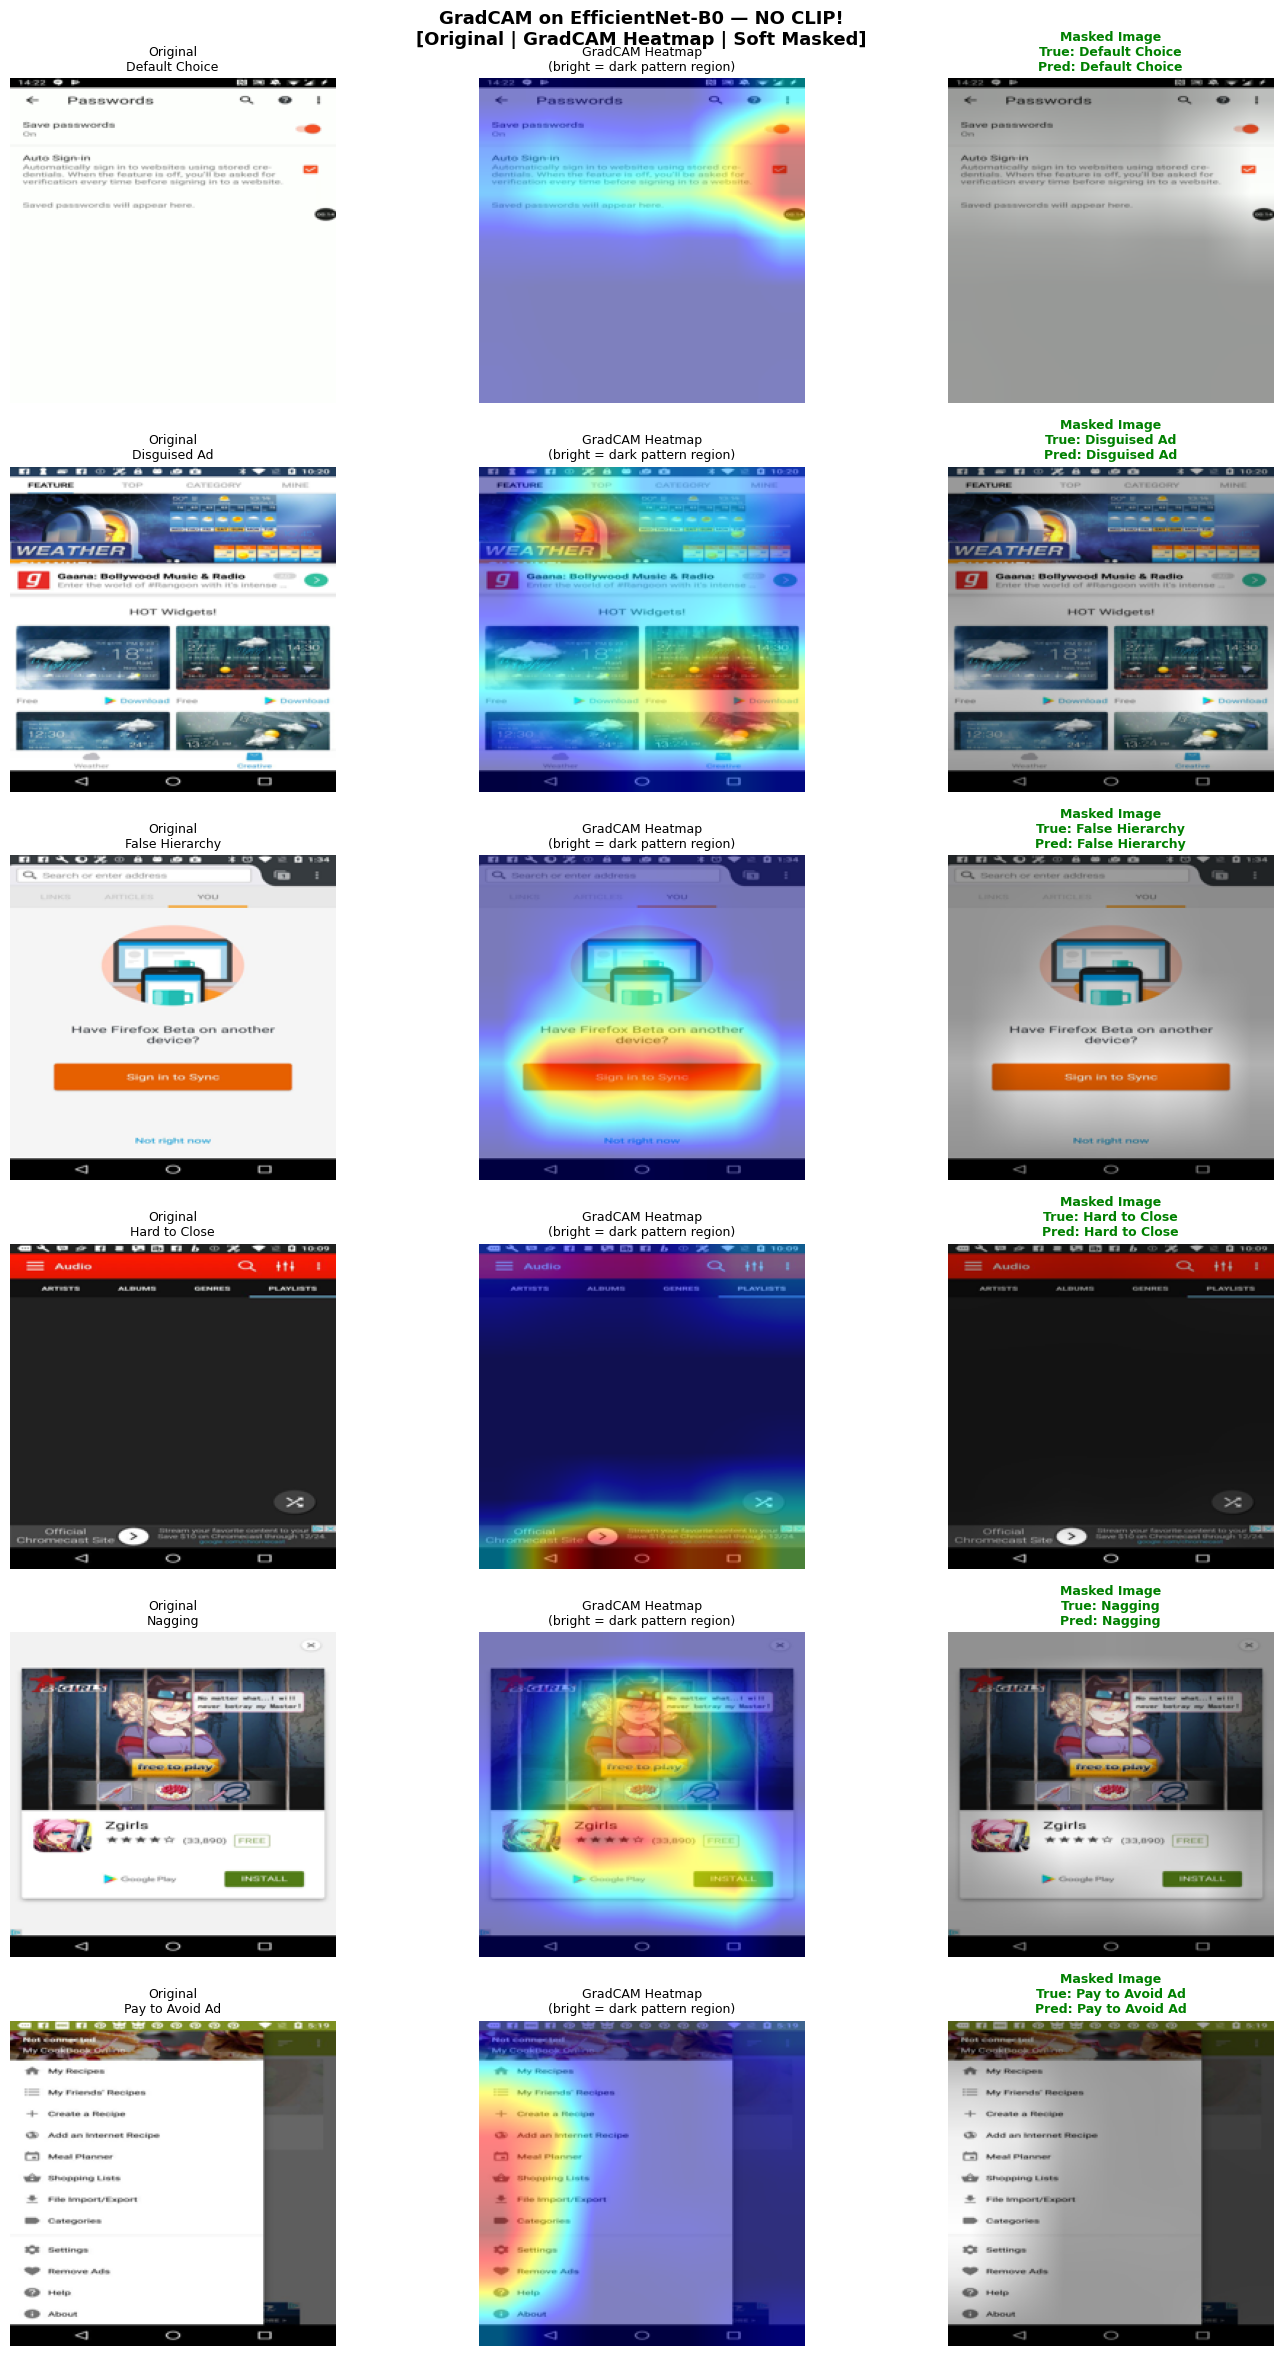

✅ GradCAM visualisation saved!
📁 /kaggle/working/dark_pattern/gradcam_noclip.png


In [31]:
## STEP 14: GradCAM on EfficientNet — Find Dark Pattern Region

import cv2
import numpy as np
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import transforms
import matplotlib.pyplot as plt
from pathlib import Path

# ── Load best model ───────────────────────────────────────────
eff_model.load_state_dict(torch.load(
    f"{WORK_DIR}/efficientnet_noclip_best.pth",
    map_location=cfg.device))
eff_model.eval()

# ── GradCAM setup ─────────────────────────────────────────────
# Hook into EfficientNet's last conv layer
# EfficientNet's last feature layer = features[-1]
gradients  = {}
activations = {}

def save_gradient(name):
    def hook(mod, grad_in, grad_out):
        gradients[name] = grad_out[0].detach()
    return hook

def save_activation(name):
    def hook(mod, inp, out):
        activations[name] = out.detach()
    return hook

# Register on last conv block of EfficientNet
target_layer = eff_model.features[-1]
fwd_hook = target_layer.register_forward_hook(save_activation("target"))
bwd_hook = target_layer.register_full_backward_hook(save_gradient("target"))

# ── Preprocessing ─────────────────────────────────────────────
infer_tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225]),
])

def generate_gradcam(image_path, label_id=None):
    """
    Runs GradCAM on EfficientNet-B0.
    No CLIP involved anywhere!

    Returns:
        img_orig    : original image as numpy array
        heatmap     : gradcam heatmap [0,1]
        masked_img  : soft masked image
        binary_mask : 1=dark pattern, 0=background
        pred_id     : predicted class id
    """
    img_pil   = Image.open(image_path).convert("RGB")
    img_orig  = np.array(img_pil.resize((224, 224)))
    img_tensor = infer_tfm(img_pil).unsqueeze(0).to(cfg.device)

    # Forward pass with gradient tracking
    eff_model.zero_grad()
    with torch.enable_grad():
        img_tensor.requires_grad_(True)
        logits  = eff_model(img_tensor)          # [1, NUM_CLASSES]
        pred_id = logits.argmax(1).item()

        # Use predicted class if no label given
        target = label_id if label_id is not None else pred_id
        score  = logits[0, target]
        score.backward()

    # ── GradCAM computation ───────────────────────────────────
    grad = gradients["target"]       # [1, C, H, W]
    act  = activations["target"]     # [1, C, H, W]

    # Global average pool gradients over spatial dims
    weights  = grad.mean(dim=[2, 3], keepdim=True)  # [1, C, 1, 1]
    cam      = (weights * act).sum(dim=1).squeeze()  # [H, W]
    cam      = F.relu(cam)                            # keep positives

    # Normalize to [0, 1]
    cam      = cam.cpu().numpy()
    cam      = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    # Resize to image size
    heatmap  = cv2.resize(cam, (224, 224))

    # ── Soft mask ─────────────────────────────────────────────
    # dark pattern region = bright, background = dimmed
    binary_mask = (heatmap >= 0.5).astype(np.uint8)
    weight      = 0.6 + (1 - 0.6) * heatmap
    weight      = weight[:, :, np.newaxis]
    masked_img  = (img_orig * weight).clip(0, 255).astype(np.uint8)

    return img_orig, heatmap, masked_img, binary_mask, pred_id


# ── Visualise GradCAM on one image per class ──────────────────
print("📸 GradCAM Results — One image per class:")
print("   (No CLIP used anywhere!)\n")

test_df = pd.read_csv(f"{WORK_DIR}/test.csv")

fig, axes = plt.subplots(len(CLASSES), 3,
                          figsize=(15, 4 * len(CLASSES)))

for i, cls in enumerate(CLASSES):
    rows = test_df[test_df["class"] == cls]
    if len(rows) == 0:
        continue

    img_path  = rows.iloc[0]["image_path"]
    label_id  = int(rows.iloc[0]["label"])

    img_orig, heatmap, masked_img, binary_mask, pred_id = \
        generate_gradcam(img_path, label_id)

    pred_cls = ID2CLASS[pred_id]
    correct  = pred_id == label_id
    color    = "green" if correct else "red"

    # Heatmap overlay on original
    heatmap_color = cv2.applyColorMap(
        (heatmap * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay       = cv2.addWeighted(img_orig, 0.5,
                                     heatmap_color, 0.5, 0)

    # Plot: Original | GradCAM Overlay | Masked
    axes[i][0].imshow(img_orig)
    axes[i][0].set_title(f"Original\n{cls}", fontsize=9)
    axes[i][0].axis("off")

    axes[i][1].imshow(overlay)
    axes[i][1].set_title(
        f"GradCAM Heatmap\n(bright = dark pattern region)",
        fontsize=9)
    axes[i][1].axis("off")

    axes[i][2].imshow(masked_img)
    axes[i][2].set_title(
        f"Masked Image\nTrue: {cls}\nPred: {pred_cls}",
        fontsize=9, color=color, fontweight="bold")
    axes[i][2].axis("off")

plt.suptitle(
    "GradCAM on EfficientNet-B0 — NO CLIP!\n"
    "[Original | GradCAM Heatmap | Soft Masked]",
    fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/gradcam_noclip.png",
            dpi=150, bbox_inches="tight")
plt.show()

# Remove hooks
fwd_hook.remove()
bwd_hook.remove()

print("✅ GradCAM visualisation saved!")
print(f"📁 {WORK_DIR}/gradcam_noclip.png")

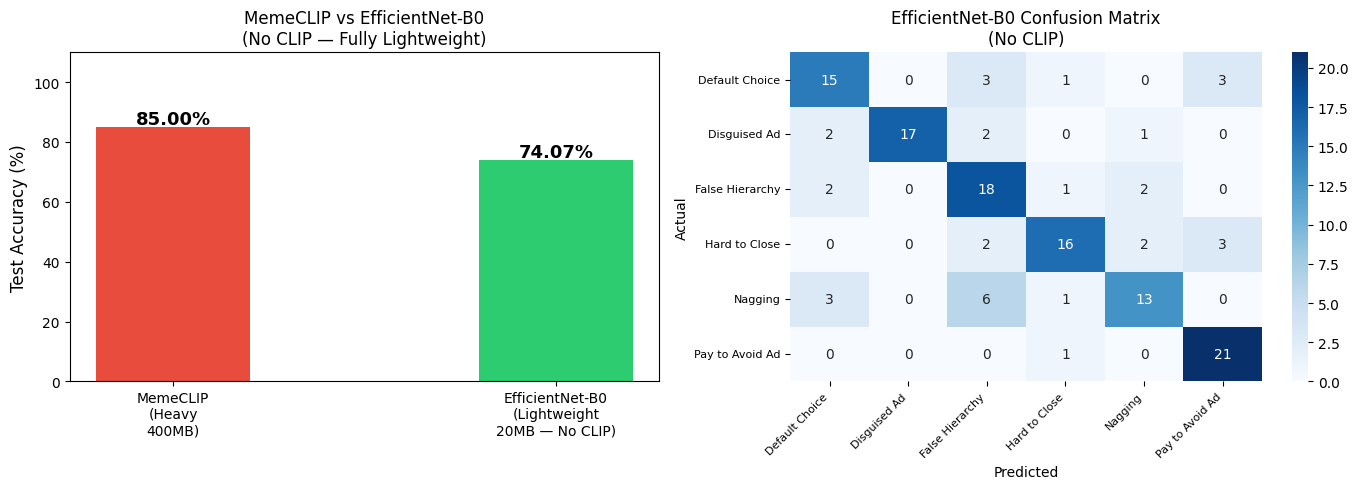

         FINAL COMPARISON — NO CLIP PIPELINE
  MemeCLIP      (heavy,  400MB, uses CLIP) : 85.00%
  EfficientNet  (light,   20MB, NO CLIP  ) : 74.07%
  Gap                                      : 10.93%

📋 Classification Report:
                 precision    recall  f1-score   support

 Default Choice       0.68      0.68      0.68        22
   Disguised Ad       1.00      0.77      0.87        22
False Hierarchy       0.58      0.78      0.67        23
  Hard to Close       0.80      0.70      0.74        23
        Nagging       0.72      0.57      0.63        23
Pay to Avoid Ad       0.78      0.95      0.86        22

       accuracy                           0.74       135
      macro avg       0.76      0.74      0.74       135
   weighted avg       0.76      0.74      0.74       135


  PIPELINE COMPARISON
                                 MemeCLIP    EfficientNet
  Model Size                     ~400MB      ~20MB
  Uses CLIP                      Yes         NO ✅
  Needs Text Input

In [ ]:
## STEP 15: Final Comparison — MemeCLIP vs EfficientNet (NO CLIP)

from sklearn.metrics import accuracy_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# ── Evaluate on test set ──────────────────────────────────────
eff_model.load_state_dict(torch.load(
    f"{WORK_DIR}/efficientnet_noclip_best.pth",
    map_location=cfg.device))
eff_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in dl_te:
        imgs  = imgs.to(cfg.device)
        preds = eff_model(imgs).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

eff_acc      = accuracy_score(all_labels, all_preds)
memeclip_acc = 0.85    # ← your actual MemeCLIP accuracy

# ── Comparison Chart ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
ax   = axes[0]
bars = ax.bar(
    ["MemeCLIP\n(Heavy\n400MB)",
     "EfficientNet-B0\n(Lightweight\n20MB — No CLIP)"],
    [memeclip_acc * 100, eff_acc * 100],
    color=["#e74c3c", "#2ecc71"], width=0.4
)
for bar, acc in zip(bars, [memeclip_acc*100, eff_acc*100]):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 1,
            f"{acc:.2f}%",
            ha="center", fontsize=13, fontweight="bold")
ax.set_ylim(0, 110)
ax.set_ylabel("Test Accuracy (%)", fontsize=12)
ax.set_title("MemeCLIP vs EfficientNet-B0\n(No CLIP — Fully Lightweight)",
             fontsize=12)

# Confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES,
            ax=axes[1])
axes[1].set_title("EfficientNet-B0 Confusion Matrix\n(No CLIP)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
plt.setp(axes[1].get_xticklabels(),
         rotation=45, ha="right", fontsize=8)
plt.setp(axes[1].get_yticklabels(),
         rotation=0, fontsize=8)

plt.tight_layout()
plt.savefig(f"{WORK_DIR}/final_comparison_noclip.png",
            dpi=150, bbox_inches="tight")
plt.show()

# ── Print results ─────────────────────────────────────────────
print("=" * 60)
print("         FINAL COMPARISON — NO CLIP PIPELINE")
print("=" * 60)
print(f"  MemeCLIP      (heavy,  400MB, uses CLIP) : {memeclip_acc*100:.2f}%")
print(f"  EfficientNet  (light,   20MB, NO CLIP  ) : {eff_acc*100:.2f}%")
print(f"  Gap                                      : {(memeclip_acc-eff_acc)*100:.2f}%")
print("=" * 60)
print()
print("📋 Classification Report:")
print(classification_report(all_labels, all_preds,
                             target_names=CLASSES,
                             zero_division=0))

print()
print("=" * 60)
print("  PIPELINE COMPARISON")
print("=" * 60)
print(f"  {'':30} MemeCLIP    EfficientNet")
print(f"  {'Model Size':30} ~400MB      ~20MB")
print(f"  {'Uses CLIP':30} Yes         NO ✅")
print(f"  {'Needs Text Input':30} Yes         NO ✅")
print(f"  {'Shows Dark Pattern Region':30} No          YES ✅")
print(f"  {'Speed':30} Slow        Fast ✅")
print(f"  {'Accuracy':30} {memeclip_acc*100:.2f}%      {eff_acc*100:.2f}%")
print("=" * 60)